# Week 7 — Downstream Evaluation Beyond Perplexity (SIB-200 & FLORES-200 Translation)

Weeks 1–6 showed large, statistically significant perplexity gaps under English-only KV-cache calibration across **Qwen3-1.7B** and **Llama-3.2-3B**, and showed that **`joint` + `protect_pos0` + `mix_5k` (`~5k` target tokens, `w = 0.10`)** closes 81–99% of the gap.

This notebook tests whether those perplexity penalties translate into **real downstream task degradation** — and whether the `5k`-token recipe recovers downstream performance — on **both models** (`Qwen/Qwen3-1.7B` and `unsloth/Llama-3.2-3B`):

1. **Task 1 — SIB-200 Topic Classification (7 classes, 204 parallel test examples/lang, 7-shot):**
   Evaluates `en`, `es`, `fi`, `qu` via 1-pass log-likelihood over the 7 distinct class-label tokens (`Accuracy`, `Macro-F1`, paired bootstrap 95% CIs).
2. **Task 2 — FLORES-200 Autoregressive Machine Translation (`qu → es`, `es → qu`, `fi → en`, `es → en`, 5-shot greedy decoding):**
   Evaluates **true autoregressive `use_cache=True` KV-cache compression** (compressing both prefill and every newly decoded token while protecting each sequence's first real sink token under left-padding!), scored with **chrF++** + paired bootstrap 95% CIs and saved sample translations.

### Two headline compression regimes (both `r = 0.25`, `protect_pos0 = True`, calibrated ONLY on Wikipedia — strict cross-domain evaluation!)
- **`V_late_head` (`layers 21–27`, `V`, `head`):** isolates late-layer value calibration bias.
- **`KV_full_joint` (`layers 3–27`, `K+V`, `joint`):** true **4× KV-cache compression** across 89% of the model.

**Kaggle settings.** GPU T4 ×1 or P100, Internet On.
Expected runtime: ~45–50 min for **both models** (`QUICK = True` cuts it to ~18 min; `SMOKE_TEST = True` runs in <30 s on CPU).

In [1]:
import os

SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"   # True for <30s CPU dry run
QUICK = False                                           # True: fewer MT examples & 1 model (~18 min)

MODELS = [
    ("qwen3_1.7b", "Qwen/Qwen3-1.7B"),
    ("llama32_3b", "unsloth/Llama-3.2-3B"),
]
if QUICK:
    MODELS = MODELS[:1]

LANGS = ["en", "es", "fi", "qu"]
FLORES_CODES = {
    "en": "eng_Latn",
    "es": "spa_Latn",
    "fi": "fin_Latn",
    "qu": "quy_Latn",
}
LANG_NAMES = {"en": "English", "es": "Spanish", "fi": "Finnish", "qu": "Quechua"}
WIKI_SNAPSHOT = "20231101"

SEQ_LEN = 512
CALIB_TOKENS = 150_000          # Wikipedia calibration budget (completely disjoint from SIB-200 / FLORES)
LOW_BUDGET_WINDOWS = 10         # ~5k tokens
MIX_WEIGHT = 0.10
MAX_TOKENS_PER_ARTICLE = 2048
MIN_CHARS_PER_ARTICLE = 500
MIN_FILL = 0.5

R_MAIN = 0.25
N_MT = 80 if not QUICK else 40  # parallel devtest sentences per translation direction
MT_MAX_NEW_TOKENS = 64
MT_SHOTS = 5
MT_DIRS = [
    ("qu", "es", "qu"),         # (src_lang, tgt_lang, focus_lang_for_matched_basis)
    ("es", "qu", "qu"),
    ("fi", "en", "fi"),
    ("es", "en", "es"),
]

SIB_CLASSES = [
    "science/technology", "travel", "politics", "sports",
    "health", "entertainment", "geography",
]
N_BOOT = 2000
SEED = 0

OUT_DIR = "/kaggle/working/kv_rank_week7_downstream" if os.path.isdir("/kaggle/working") else "./kv_rank_week7_downstream"
os.makedirs(OUT_DIR, exist_ok=True)

if SMOKE_TEST:
    MODELS = [("smoke_llama", "smoke")]
    LANGS = ["aa", "bb", "cc"]
    FLORES_CODES = {"aa": "aa", "bb": "bb", "cc": "cc"}
    LANG_NAMES = {"aa": "AA", "bb": "BB", "cc": "CC"}
    SEQ_LEN, CALIB_TOKENS, LOW_BUDGET_WINDOWS = 64, 64 * 16, 4
    N_MT, MT_MAX_NEW_TOKENS, MT_SHOTS, N_BOOT = 8, 12, 2, 200
    MT_DIRS = [("cc", "aa", "cc"), ("bb", "aa", "bb")]

print(f"SMOKE_TEST={SMOKE_TEST} | QUICK={QUICK} | models={[m[0] for m in MODELS]} | output -> {OUT_DIR}")

SMOKE_TEST=False | QUICK=False | models=['qwen3_1.7b', 'llama32_3b'] | output -> /kaggle/working/kv_rank_week7_downstream


In [2]:
import collections, csv, gc, io, itertools, json, math, tarfile, time, urllib.request, zlib
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch:", torch.__version__)

device: cuda | torch: 2.11.0+cu130


## 1. Downstream Datasets (SIB-200 & FLORES-200) + Pure-Python chrF++

- **SIB-200** (`Davlan/sib200`, with automatic fallback to official `dadelani/sib-200` GitHub TSVs): 7-class topic classification over FLORES-200 sentences (`204` parallel test examples per language; 7-shot demonstrations drawn from `train`).
- **FLORES-200** (official Meta tarball + Parquet fallback): `dev` supplies fixed 5-shot translation demonstrations, `devtest` supplies `N_MT` parallel evaluation sentences.
- **chrF++** (Popović 2017): character n-grams `1..6` + word n-grams `1..2`, $\beta = 2$ — zero extra pip dependencies.

In [3]:
FLORES_CACHE = os.path.join(OUT_DIR, "_flores200")


def _download_flores_tarball():
    dev_dir = os.path.join(FLORES_CACHE, "flores200_dataset", "dev")
    if os.path.isdir(dev_dir):
        return os.path.join(FLORES_CACHE, "flores200_dataset")
    os.makedirs(FLORES_CACHE, exist_ok=True)
    tgz = os.path.join(FLORES_CACHE, "flores200_dataset.tar.gz")
    for url in (
        "https://dl.fbaipublicfiles.com/nllb/flores200_dataset.tar.gz",
        "https://tinyurl.com/flores200dataset",
    ):
        try:
            urllib.request.urlretrieve(url, tgz)
            with tarfile.open(tgz, "r:gz") as tf:
                try:
                    tf.extractall(FLORES_CACHE, filter="data")
                except TypeError:
                    tf.extractall(FLORES_CACHE)
            if os.path.isdir(dev_dir):
                return os.path.join(FLORES_CACHE, "flores200_dataset")
        except Exception as e:
            print(f"  FLORES tarball failed ({url}): {e}")
    return None


def load_flores_sentences(code, split):
    root = _download_flores_tarball()
    if root is not None:
        p = os.path.join(root, split, f"{code}.{split}")
        if os.path.isfile(p):
            with open(p, encoding="utf-8") as fh:
                return [line.strip() for line in fh if line.strip()]
    from datasets import load_dataset
    sp = "validation" if split == "dev" else "test"
    ds = load_dataset("tomasmajercik/flores-parquet", name=code, split=sp)
    col = next(c for c in ("sentence", "text", "target", "source") if c in ds.column_names)
    return [str(x).strip() for x in ds[col]]


def load_sib200(code):
    """Return {'train': [(text, category), ...], 'test': [(text, category), ...]}."""
    from datasets import load_dataset
    try:
        ds = load_dataset("Davlan/sib200", code)
        out = {}
        for sp in ("train", "test"):
            d = ds[sp]
            cat_col = "category" if "category" in d.column_names else "label"
            feat = d.features.get(cat_col)
            rows = []
            for row in d:
                c = row[cat_col]
                if isinstance(c, int) and hasattr(feat, "int2str"):
                    c = feat.int2str(c)
                rows.append((str(row["text"]).strip(), str(c).strip().lower()))
            out[sp] = rows
        return out
    except Exception as e:
        print(f"  HF Davlan/sib200 fallback for {code} ({e}); trying official GitHub TSVs...")
        out = {}
        for sp in ("train", "test"):
            url = f"https://raw.githubusercontent.com/dadelani/sib-200/main/data/annotated/{code}/{sp}.tsv"
            raw = urllib.request.urlopen(url).read().decode("utf-8")
            reader = csv.DictReader(io.StringIO(raw), delimiter="\t")
            out[sp] = [(r["text"].strip(), r["category"].strip().lower()) for r in reader]
        return out


# Pure-Python corpus & sentence chrF++ (Popovic 2017: char 1..6 + word 1..2, beta=2)
def _ngrams(seq, n):
    return collections.Counter(tuple(seq[i:i + n]) for i in range(len(seq) - n + 1)) if len(seq) >= n else collections.Counter()


def _chrf_counts(hyp, ref, char_order=6, word_order=2):
    hyp_c, ref_c = hyp.strip(), ref.strip()
    hyp_w, ref_w = hyp_c.split(), ref_c.split()
    stats = []
    for n in range(1, char_order + 1):
        hc, rc = _ngrams(hyp_c, n), _ngrams(ref_c, n)
        m = sum((hc & rc).values())
        stats.append((m, sum(hc.values()), sum(rc.values())))
    for n in range(1, word_order + 1):
        hw, rw = _ngrams(hyp_w, n), _ngrams(ref_w, n)
        m = sum((hw & rw).values())
        stats.append((m, sum(hw.values()), sum(rw.values())))
    return stats


def corpus_chrfpp(hyps, refs, char_order=6, word_order=2, beta=2.0):
    total_orders = char_order + word_order
    tot_m = [0] * total_orders
    tot_h = [0] * total_orders
    tot_r = [0] * total_orders
    for h, r in zip(hyps, refs):
        for k, (m, hc, rc) in enumerate(_chrf_counts(h, r, char_order, word_order)):
            tot_m[k] += m; tot_h[k] += hc; tot_r[k] += rc
    precs, recs = [], []
    for k in range(total_orders):
        if tot_h[k] > 0 or tot_r[k] > 0:
            precs.append(tot_m[k] / tot_h[k] if tot_h[k] > 0 else 0.0)
            recs.append(tot_m[k] / tot_r[k] if tot_r[k] > 0 else 0.0)
    if not precs:
        return 0.0
    avg_p = sum(precs) / len(precs)
    avg_r = sum(recs) / len(recs)
    if avg_p + avg_r == 0:
        return 0.0
    b2 = beta * beta
    return 100.0 * (1.0 + b2) * avg_p * avg_r / (b2 * avg_p + avg_r)


def sentence_chrfpp(hyp, ref):
    return corpus_chrfpp([hyp], [ref])


def macro_f1(y_true, y_pred, n_classes):
    f1s = []
    for c in range(n_classes):
        tp = sum((yt == c) and (yp == c) for yt, yp in zip(y_true, y_pred))
        fp = sum((yt != c) and (yp == c) for yt, yp in zip(y_true, y_pred))
        fn = sum((yt == c) and (yp != c) for yt, yp in zip(y_true, y_pred))
        p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1s.append(2 * p * r / (p + r) if (p + r) > 0 else 0.0)
    return 100.0 * float(np.mean(f1s))


rng = np.random.default_rng(SEED)


def paired_boot(a, b):
    d = np.asarray(a, dtype=np.float64) - np.asarray(b, dtype=np.float64)
    boots = d[rng.integers(0, len(d), size=(N_BOOT, len(d)))].mean(1)
    return float(d.mean()), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))


# Load SIB-200 and FLORES-200 once (shared across models)
sib_data, flores_sents = {}, {}
if SMOKE_TEST:
    for lang in LANGS:
        sib_data[lang] = {
            "train": [(f"sample {lang} text about {c} {i}", c) for i, c in enumerate(SIB_CLASSES)],
            "test": [(f"test {lang} text {i} {SIB_CLASSES[i % len(SIB_CLASSES)]}", SIB_CLASSES[i % len(SIB_CLASSES)]) for i in range(14)],
        }
        flores_sents[lang] = {
            "dev": [f"dev {lang} sentence number {i}" for i in range(10)],
            "devtest": [f"test {lang} sentence number {i}" for i in range(N_MT)],
        }
else:
    for lang in LANGS:
        t0 = time.time()
        sib_data[lang] = load_sib200(FLORES_CODES[lang])
        flores_sents[lang] = {
            "dev": load_flores_sentences(FLORES_CODES[lang], "dev"),
            "devtest": load_flores_sentences(FLORES_CODES[lang], "devtest")[:N_MT],
        }
        print(f"{lang}: SIB-200 train={len(sib_data[lang]['train'])} test={len(sib_data[lang]['test'])} | "
              f"FLORES dev={len(flores_sents[lang]['dev'])} devtest={len(flores_sents[lang]['devtest'])} ({time.time()-t0:.0f}s)")

README.md:   0%|          | 0.00/47.9k [00:00<?, ?B/s]

train.tsv:   0%|          | 0.00/103k [00:00<?, ?B/s]

dev.tsv:   0%|          | 0.00/13.6k [00:00<?, ?B/s]

test.tsv:   0%|          | 0.00/30.1k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

... (19 outputs left out)

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

qu: SIB-200 train=701 test=204 | FLORES dev=997 devtest=80 (1s)


## 2. Sink-Preserving KV-Cache Projection Engine (Prefill + Autoregressive Decode)

Key detail for real `use_cache=True` batched generation with left-padding:
- On the **prefill step** (`step_pos == 0`), each batch row's first real (non-pad) token sits at `sink_idx[b] = first_non_pad_position(attention_mask[b])`. The hook projects the entire prefill tensor and restores `out[b, sink_idx[b], :]` untouched.
- On every **autoregressive decode step** (`step_pos > 0`, `T == 1`), the newly generated token is at sequence position `>= 1`, so the hook projects it into the low-rank subspace before it enters `DynamicCache`.

In [4]:
from transformers import AutoModelForCausalLM, AutoTokenizer


def wiki_calib_windows(lang, tokenizer):
    if SMOKE_TEST:
        lo = {"aa": 0, "bb": 300, "cc": 600}[lang]
        g = torch.Generator().manual_seed(SEED + lo)
        return torch.randint(lo, lo + 300, (CALIB_TOKENS // SEQ_LEN, SEQ_LEN), generator=g)
    from datasets import load_dataset
    ds = load_dataset("wikimedia/wikipedia", f"{WIKI_SNAPSHOT}.{lang}", split="train", streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=2000)
    need = CALIB_TOKENS // SEQ_LEN
    win = []
    for row in ds:
        if len(row["text"]) < MIN_CHARS_PER_ARTICLE:
            continue
        if zlib.crc32(str(row["id"]).encode()) % 2 != 0:
            continue  # use exact same calibration split as Weeks 2-6
        ids = tokenizer(row["text"], add_special_tokens=False)["input_ids"][:MAX_TOKENS_PER_ARTICLE]
        for i in range(0, len(ids) - SEQ_LEN + 1, SEQ_LEN):
            win.append(ids[i:i + SEQ_LEN])
            if len(win) >= need:
                return torch.tensor(win, dtype=torch.long)
    if len(win) < MIN_FILL * need:
        raise RuntimeError(f"{lang}: only {len(win)}/{need} calib windows")
    return torch.tensor(win, dtype=torch.long)


def top_basis(G, r):
    lam, U = np.linalg.eigh(G)
    return U[:, ::-1][:, :r]


def blocks(G, n_kv, hd):
    return [G[h * hd:(h + 1) * hd, h * hd:(h + 1) * hd] for h in range(n_kv)]


def make_projector(G_layer, scope, f, n_kv, hd, d_kv, dtype):
    if scope == "head":
        r = max(1, round(f * hd))
        P = np.stack([(lambda U: U @ U.T)(top_basis(B, r)) for B in blocks(G_layer, n_kv, hd)])
    else:
        r = max(1, round(f * d_kv))
        U = top_basis(G_layer, r)
        P = U @ U.T
    return torch.tensor(P, dtype=dtype, device=device)


class SinkAwareKVProjector:
    """Context manager applying low-rank projection during both prefill and use_cache=True decode."""
    def __init__(self, proj_mods, gram_src, kinds, layers, scope, f, n_kv, hd, d_kv, dtype):
        self.proj_mods = proj_mods
        self.kinds = kinds
        self.layers = layers
        self.scope = scope
        self.n_kv, self.hd, self.d_kv = n_kv, hd, d_kv
        self.projectors = {
            (k, l): make_projector(gram_src[k][l], scope, f, n_kv, hd, d_kv, dtype)
            for k in kinds for l in layers
        }
        self.handles = []
        self.step_pos = {}
        self.sink_idx = None  # 1D LongTensor of shape (B,) giving first real token per batch row

    def reset_call(self, sink_idx):
        self.step_pos = {(k, l): 0 for k in self.kinds for l in self.layers}
        self.sink_idx = sink_idx

    def _hook(self, k, l):
        P = self.projectors[(k, l)]
        def fn(mod, inp, out):
            pos = self.step_pos[(k, l)]
            B, T, _ = out.shape
            self.step_pos[(k, l)] = pos + T
            if self.scope == "head":
                proj = torch.einsum("btnd,nde->btne", out.reshape(B, T, self.n_kv, self.hd), P).reshape(B, T, self.d_kv)
            else:
                proj = out @ P
            if pos == 0:
                if self.sink_idx is None:
                    proj[:, 0, :] = out[:, 0, :]
                else:
                    b_idx = torch.arange(B, device=out.device)
                    proj[b_idx, self.sink_idx, :] = out[b_idx, self.sink_idx, :]
            return proj
        return fn

    def __enter__(self):
        for k in self.kinds:
            for l in self.layers:
                self.handles.append(self.proj_mods[k][l].register_forward_hook(self._hook(k, l)))
        return self

    def __exit__(self, *exc):
        for h in self.handles:
            h.remove()
        self.handles.clear()


def avg_grams(glist):
    return {k: sum(g[k] for g in glist) / len(glist) for k in ("K", "V")}


def mix_grams(g_other, g_tgt, w):
    return {k: (1.0 - w) * g_other[k] + w * g_tgt[k] for k in ("K", "V")}


def get_source_gram(gram_cal, gram_5k, src, tgt):
    if src == "matched":   return gram_cal[tgt]
    if src == "multi":     return avg_grams([gram_cal[l] for l in LANGS])
    if src == "multi_loo": return avg_grams([gram_cal[l] for l in LANGS if l != tgt])
    if src == "mix_5k":
        return mix_grams(avg_grams([gram_cal[l] for l in LANGS if l != tgt]), gram_5k[tgt], MIX_WEIGHT)
    return gram_cal[src]


def build_sib_prompt_prefix(train_rows):
    # Pick 1 fixed demonstration per class from train split
    demos = []
    for cls in SIB_CLASSES:
        for txt, c in train_rows:
            if c == cls:
                demos.append((txt, cls))
                break
    header = "Classify the topic of the text into one of: " + ", ".join(SIB_CLASSES) + ".\n\n"
    body = "".join(f"Text: {t}\nTopic: {c}\n\n" for t, c in demos)
    return header + body


@torch.no_grad()
def eval_sib200(model, tokenizer, lang, proj_ctx=None, batch_size=4):
    test_rows = sib_data[lang]["test"]
    y_true = [SIB_CLASSES.index(c) for _, c in test_rows]
    if SMOKE_TEST:
        # Synthetic token IDs with 7 fixed candidate label token IDs
        label_ids = torch.tensor([10, 11, 12, 13, 14, 15, 16], device=device)
        preds = []
        g = torch.Generator().manual_seed(SEED + hash(lang) % 1000)
        for i in range(0, len(test_rows), batch_size):
            bs = min(batch_size, len(test_rows) - i)
            ids = torch.randint(20, 300, (bs, 32), generator=g).to(device)
            if proj_ctx is not None:
                proj_ctx.reset_call(torch.zeros(bs, dtype=torch.long, device=device))
            logits = model(input_ids=ids, use_cache=False).logits[:, -1, label_ids]
            preds.extend(logits.argmax(dim=-1).cpu().tolist())
        correct = [int(a == b) for a, b in zip(preds, y_true)]
        return 100.0 * float(np.mean(correct)), macro_f1(y_true, preds, len(SIB_CLASSES)), correct

    prefix = build_sib_prompt_prefix(sib_data[lang]["train"])
    prompts = [prefix + f"Text: {txt}\nTopic:" for txt, _ in test_rows]
    # All 7 class labels start with 7 distinct single tokens after a leading space
    label_tok_ids = [tokenizer(" " + cls, add_special_tokens=False)["input_ids"][0] for cls in SIB_CLASSES]
    assert len(set(label_tok_ids)) == len(SIB_CLASSES), f"Non-unique class first tokens: {label_tok_ids}"
    label_ids_t = torch.tensor(label_tok_ids, device=device)

    old_side = tokenizer.padding_side
    tokenizer.padding_side = "left"
    preds = []
    try:
        for i in range(0, len(prompts), batch_size):
            enc = tokenizer(prompts[i:i + batch_size], return_tensors="pt", padding=True, truncation=True, max_length=1024).to(device)
            if proj_ctx is not None:
                sink_idx = (enc["attention_mask"].cumsum(dim=1) == 1).long().argmax(dim=1)
                proj_ctx.reset_call(sink_idx)
            logits = model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"], use_cache=False).logits
            # With left padding, the last position (-1) is always the final real prompt token
            scores = logits[:, -1, label_ids_t]
            preds.extend(scores.argmax(dim=-1).cpu().tolist())
    finally:
        tokenizer.padding_side = old_side

    correct = [int(a == b) for a, b in zip(preds, y_true)]
    return 100.0 * float(np.mean(correct)), macro_f1(y_true, preds, len(SIB_CLASSES)), correct


@torch.no_grad()
def eval_flores_mt(model, tokenizer, src_lang, tgt_lang, proj_ctx=None, batch_size=8):
    src_dev = flores_sents[src_lang]["dev"][:MT_SHOTS]
    tgt_dev = flores_sents[tgt_lang]["dev"][:MT_SHOTS]
    src_test = flores_sents[src_lang]["devtest"]
    tgt_test = flores_sents[tgt_lang]["devtest"]

    if SMOKE_TEST:
        hyps = []
        g = torch.Generator().manual_seed(SEED + 77)
        for i in range(0, len(src_test), batch_size):
            bs = min(batch_size, len(src_test) - i)
            ids = torch.randint(10, 300, (bs, 24), generator=g).to(device)
            if proj_ctx is not None:
                proj_ctx.reset_call(torch.zeros(bs, dtype=torch.long, device=device))
            out = model.generate(input_ids=ids, max_new_tokens=MT_MAX_NEW_TOKENS, do_sample=False, use_cache=True)
            for row in out[:, ids.shape[1]:]:
                hyps.append(" ".join(str(x) for x in row.cpu().tolist()[:8]))
        sent_scores = [sentence_chrfpp(h, r) for h, r in zip(hyps, tgt_test)]
        return corpus_chrfpp(hyps, tgt_test), sent_scores, hyps[:5]

    sn, tn = LANG_NAMES[src_lang], LANG_NAMES[tgt_lang]
    prefix = f"Translate the following sentences from {sn} to {tn}.\n\n"
    for s, t in zip(src_dev, tgt_dev):
        prefix += f"{sn}: {s}\n{tn}: {t}\n\n"
    prompts = [prefix + f"{sn}: {s}\n{tn}:" for s in src_test]

    old_side = tokenizer.padding_side
    tokenizer.padding_side = "left"
    hyps = []
    nl_id = tokenizer.encode("\n", add_special_tokens=False)
    base_eos = tokenizer.eos_token_id
    eos_ids = list(base_eos) if isinstance(base_eos, (list, tuple)) else ([base_eos] if base_eos is not None else [])
    if nl_id:
        eos_ids.append(nl_id[-1])
    eos_ids = list(dict.fromkeys([x for x in eos_ids if x is not None]))
    try:
        for i in range(0, len(prompts), batch_size):
            enc = tokenizer(prompts[i:i + batch_size], return_tensors="pt", padding=True, truncation=True, max_length=1024).to(device)
            if proj_ctx is not None:
                sink_idx = (enc["attention_mask"].cumsum(dim=1) == 1).long().argmax(dim=1)
                proj_ctx.reset_call(sink_idx)
            gen = model.generate(
                input_ids=enc["input_ids"],
                attention_mask=enc["attention_mask"],
                max_new_tokens=MT_MAX_NEW_TOKENS,
                do_sample=False,
                use_cache=True,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=eos_ids,
            )
            new_toks = gen[:, enc["input_ids"].shape[1]:]
            for row in new_toks:
                txt = tokenizer.decode(row, skip_special_tokens=True).strip()
                txt = txt.split("\n")[0].strip()
                hyps.append(txt)
    finally:
        tokenizer.padding_side = old_side

    sent_scores = [sentence_chrfpp(h, r) for h, r in zip(hyps, tgt_test)]
    return corpus_chrfpp(hyps, tgt_test), sent_scores, hyps[:5]

## 3. Run Both Models (Qwen3-1.7B & Llama-3.2-3B)

For each model:
1. Collect Wikipedia calibration Grams (`150k` tokens + `5k` snapshot) with `SKIP_FIRST_TOKENS = 1`.
2. Evaluate **SIB-200** (`en`, `es`, `fi`, `qu`) and **FLORES-200 translation** (`qu → es`, `es → qu`, `fi → en`, `es → en`) across:
   - `uncompressed` (baseline)
   - `V_late_head` (`layers 21–27`, `V`, `head`, `r = 0.25`, `protect_pos0 = True`)
   - `KV_full_joint` (`layers 3–27`, `K+V`, `joint`, `r = 0.25`, `protect_pos0 = True`)
   - Calibration sources: `matched`, `en`, `multi_loo`, `mix_5k` (`w = 0.10`), `multi`.

In [5]:
en_code = LANGS[0]
SOURCES = ["matched", en_code, "multi_loo", "mix_5k", "multi"]

all_sib_rows, all_mt_rows, sample_translations = [], [], {}

for model_tag, model_id in MODELS:
    print(f"\n{'='*72}\nMODEL: {model_tag} ({model_id})\n{'='*72}")
    t_model = time.time()

    if SMOKE_TEST:
        from transformers import LlamaConfig, LlamaForCausalLM
        model = LlamaForCausalLM(LlamaConfig(
            vocab_size=1000, hidden_size=64, intermediate_size=128,
            num_hidden_layers=4, num_attention_heads=4,
            num_key_value_heads=2, max_position_embeddings=256,
        ))
        tokenizer = None
    else:
        tokenizer = AutoTokenizer.from_pretrained(model_id)
        if tokenizer.pad_token_id is None:
            tokenizer.pad_token = tokenizer.eos_token
        half = torch.float16 if device == "cuda" else torch.float32
        try:
            model = AutoModelForCausalLM.from_pretrained(model_id, dtype=half)
        except TypeError:
            model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=half)

    model.to(device).eval()
    cfg = model.config
    N_LAYERS = cfg.num_hidden_layers
    N_KV = getattr(cfg, "num_key_value_heads", None) or cfg.num_attention_heads
    HEAD_DIM = getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads
    D_KV = N_KV * HEAD_DIM
    LATE = list(range(int(round(0.75 * N_LAYERS)), N_LAYERS))
    NO_SINK = list(range(min(3, N_LAYERS - 1), N_LAYERS))
    dtype = next(model.parameters()).dtype

    PROJ = {"K": [], "V": []}
    for name, mod in model.named_modules():
        if name.endswith("self_attn.k_proj"): PROJ["K"].append(mod)
        elif name.endswith("self_attn.v_proj"): PROJ["V"].append(mod)
    assert len(PROJ["K"]) == len(PROJ["V"]) == N_LAYERS

    # Adjust batch sizes for 3B vs 1.7B on 16 GB T4
    is_3b = "3b" in model_tag.lower()
    calib_bs = 4 if is_3b else 8
    sib_bs = 2 if is_3b else 4
    mt_bs = 8 if not is_3b else 4

    # 1) Collect Wikipedia calibration Grams (150k + 5k snap)
    gram_cal, gram_5k = {}, {}
    for lang in LANGS:
        t0 = time.time()
        w_cal = wiki_calib_windows(lang, tokenizer)
        acc = {k: torch.zeros(N_LAYERS, D_KV, D_KV, dtype=torch.float64, device=device) for k in ("K", "V")}
        n_tok = [0]
        def mk_h(k, l):
            def fn(mod, inp, out):
                x = out[:, 1:, :].reshape(-1, D_KV).float()
                acc[k][l] += (x.T @ x).double()
                if k == "K" and l == 0:
                    n_tok[0] += x.shape[0]
            return fn
        hs = [m.register_forward_hook(mk_h(k, l)) for k in ("K", "V") for l, m in enumerate(PROJ[k])]
        try:
            with torch.no_grad():
                for i in range(0, LOW_BUDGET_WINDOWS, calib_bs):
                    model(input_ids=w_cal[i:min(i + calib_bs, LOW_BUDGET_WINDOWS)].to(device), use_cache=False)
                gram_5k[lang] = {k: (g / n_tok[0]).cpu().numpy() for k, g in acc.items()}
                for i in range(LOW_BUDGET_WINDOWS, len(w_cal), calib_bs):
                    model(input_ids=w_cal[i:i + calib_bs].to(device), use_cache=False)
                gram_cal[lang] = {k: (g / n_tok[0]).cpu().numpy() for k, g in acc.items()}
        finally:
            for h in hs: h.remove()
        print(f"  calib {lang}: {len(w_cal)} windows ({time.time()-t0:.0f}s)")
    if device == "cuda": torch.cuda.empty_cache()

    REGIMES = [
        ("V_late_head",   ("V",),      LATE,    "head"),
        ("KV_full_joint", ("K", "V"),  NO_SINK, "joint"),
    ]

    # 2) Task 1: SIB-200 Topic Classification
    print(f"\n--- [{model_tag}] Task 1: SIB-200 Topic Classification ---")
    t_sib = time.time()
    sib_correct_store = {}
    sib_rows_m = []
    for lang in LANGS:
        acc0, f10, corr0 = eval_sib200(model, tokenizer, lang, proj_ctx=None, batch_size=sib_bs)
        sib_correct_store[("uncompressed", lang, "uncompressed")] = corr0
        sib_rows_m.append(dict(model=model_tag, regime="uncompressed", target=lang, source="uncompressed",
                               acc=acc0, macro_f1=f10))
        for rname, kinds, layers, scope in REGIMES:
            for src in SOURCES:
                if src == en_code and lang == en_code:
                    continue
                gsrc = get_source_gram(gram_cal, gram_5k, src, lang)
                with SinkAwareKVProjector(PROJ, gsrc, kinds, layers, scope, R_MAIN, N_KV, HEAD_DIM, D_KV, dtype) as ctx:
                    acc, f1, corr = eval_sib200(model, tokenizer, lang, proj_ctx=ctx, batch_size=sib_bs)
                sib_correct_store[(rname, lang, src)] = corr
                sib_rows_m.append(dict(model=model_tag, regime=rname, target=lang, source=src,
                                       acc=acc, macro_f1=f1))
    # Paired bootstrap delta accuracy vs matched (in percentage points)
    for r in sib_rows_m:
        if r["regime"] == "uncompressed" or r["source"] == "matched":
            r["delta_acc"], r["ci_low"], r["ci_high"] = np.nan, np.nan, np.nan
        else:
            d, lo, hi = paired_boot(
                [100.0 * x for x in sib_correct_store[(r["regime"], r["target"], r["source"])]],
                [100.0 * x for x in sib_correct_store[(r["regime"], r["target"], "matched")]],
            )
            r["delta_acc"], r["ci_low"], r["ci_high"] = d, lo, hi
    all_sib_rows.extend(sib_rows_m)
    sib_df_m = pd.DataFrame(sib_rows_m)
    print(f"  SIB-200 done in {(time.time()-t_sib)/60:.1f} min")
    display(sib_df_m.pivot_table(index=["regime", "target"], columns="source", values="acc").round(1))

    # 3) Task 2: FLORES-200 Autoregressive Translation
    print(f"\n--- [{model_tag}] Task 2: FLORES-200 Translation (N={N_MT}, use_cache=True) ---")
    t_mt = time.time()
    mt_score_store = {}
    mt_rows_m = []
    sample_translations[model_tag] = {}
    for src_l, tgt_l, focus_l in MT_DIRS:
        dname = f"{src_l}->{tgt_l}"
        sample_translations[model_tag][dname] = {"refs": flores_sents[tgt_l]["devtest"][:5]}
        chrf0, s0, ex0 = eval_flores_mt(model, tokenizer, src_l, tgt_l, proj_ctx=None, batch_size=mt_bs)
        mt_score_store[("uncompressed", dname, "uncompressed")] = s0
        sample_translations[model_tag][dname]["uncompressed"] = ex0
        mt_rows_m.append(dict(model=model_tag, regime="uncompressed", direction=dname, focus_lang=focus_l,
                              source="uncompressed", chrfpp=chrf0))
        for rname, kinds, layers, scope in REGIMES:
            for src in SOURCES:
                gsrc = get_source_gram(gram_cal, gram_5k, src, focus_l)
                with SinkAwareKVProjector(PROJ, gsrc, kinds, layers, scope, R_MAIN, N_KV, HEAD_DIM, D_KV, dtype) as ctx:
                    chrf, sc, ex = eval_flores_mt(model, tokenizer, src_l, tgt_l, proj_ctx=ctx, batch_size=mt_bs)
                mt_score_store[(rname, dname, src)] = sc
                if src in ("matched", en_code, "mix_5k"):
                    sample_translations[model_tag][dname][f"{rname}|{src}"] = ex
                mt_rows_m.append(dict(model=model_tag, regime=rname, direction=dname, focus_lang=focus_l,
                                      source=src, chrfpp=chrf))
        print(f"  MT {dname} done ({(time.time()-t_mt)/60:.1f} min elapsed)")

    for r in mt_rows_m:
        if r["regime"] == "uncompressed" or r["source"] == "matched":
            r["delta_chrf"], r["ci_low"], r["ci_high"] = np.nan, np.nan, np.nan
        else:
            d, lo, hi = paired_boot(
                mt_score_store[(r["regime"], r["direction"], r["source"])],
                mt_score_store[(r["regime"], r["direction"], "matched")],
            )
            r["delta_chrf"], r["ci_low"], r["ci_high"] = d, lo, hi
    all_mt_rows.extend(mt_rows_m)
    mt_df_m = pd.DataFrame(mt_rows_m)
    print(f"  MT done in {(time.time()-t_mt)/60:.1f} min | Model total: {(time.time()-t_model)/60:.1f} min")
    display(mt_df_m.pivot_table(index=["regime", "direction"], columns="source", values="chrfpp").round(2))

    # Save incrementally after each model so nothing is lost
    pd.DataFrame(all_sib_rows).to_csv(os.path.join(OUT_DIR, "sib200_results.csv"), index=False)
    pd.DataFrame(all_mt_rows).to_csv(os.path.join(OUT_DIR, "mt_flores_results.csv"), index=False)
    with open(os.path.join(OUT_DIR, "mt_sample_outputs.json"), "w", encoding="utf-8") as fh:
        json.dump(sample_translations, fh, indent=2, ensure_ascii=False)

    # Free VRAM before next model
    del model, gram_cal, gram_5k
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()

sib_df = pd.DataFrame(all_sib_rows)
mt_df = pd.DataFrame(all_mt_rows)


MODEL: qwen3_1.7b (Qwen/Qwen3-1.7B)


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

... (33 outputs left out)

  MT fi->en done (55.8 min elapsed)


[transformers] Both `max_new_tokens` (=64) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hug

  MT es->en done (72.2 min elapsed)
  MT done in 72.2 min | Model total: 115.7 min


source                      en  matched  mix_5k  multi  multi_loo  \
regime        direction                                             
KV_full_joint es->en     42.23    42.32   46.17  47.25      46.31   
              es->qu     10.26    16.59   14.90  14.58      16.19   
              fi->en     29.63    33.17   38.58  38.73      37.38   
              qu->es     14.01    20.66   24.14  23.46      23.12   
V_late_head   es->en     59.00    58.90   58.99  58.74      59.05   
              es->qu     15.39    15.67   14.88  15.00      17.72   
              fi->en     52.73    52.77   52.59  51.67      52.60   
              qu->es     27.33    26.70   27.48  27.47      26.64   
uncompressed  es->en       NaN      NaN     NaN    NaN        NaN   
              es->qu       NaN      NaN     NaN    NaN        NaN   
              fi->en       NaN      NaN     NaN    NaN        NaN   
              qu->es       NaN      NaN     NaN    NaN        NaN   

source                   uncompressed  
regime        direction                
KV_full_joint es->en              NaN  
              es->qu              NaN  
              fi->en              NaN  
              qu->es              NaN  
V_late_head   es->en              NaN  
              es->qu              NaN  
              fi->en              NaN  
              qu->es              NaN  
uncompressed  es->en            59.92  
              es->qu            19.98  
              fi->en            55.02  
              qu->es            27.47

In [6]:
print("=== SIB-200 Accuracy (%) across models & regimes ===")
display(sib_df.pivot_table(index=["model", "regime", "target"], columns="source", values="acc").round(1))

print("\n=== SIB-200 Paired Δ Accuracy vs matched (percentage points, 95% CI) ===")
display(sib_df[sib_df.source.isin([en_code, "multi_loo", "mix_5k", "multi"])][
    ["model", "regime", "target", "source", "delta_acc", "ci_low", "ci_high"]
].round(2))

print("\n=== FLORES-200 Translation chrF++ across models & regimes ===")
display(mt_df.pivot_table(index=["model", "regime", "direction"], columns="source", values="chrfpp").round(2))

print("\n=== FLORES-200 Translation Paired Δ sentence-chrF++ vs matched (95% CI) ===")
display(mt_df[mt_df.source.isin([en_code, "multi_loo", "mix_5k", "multi"])][
    ["model", "regime", "direction", "source", "delta_chrf", "ci_low", "ci_high"]
].round(2))

# Show 2 qualitative translation examples per model for the first direction (qu->es)
d0 = f"{MT_DIRS[0][0]}->{MT_DIRS[0][1]}"
for mtag in [m[0] for m in MODELS]:
    print(f"\n--- Sample translations [{mtag}, {d0}] ---")
    ex = sample_translations[mtag][d0]
    for idx in range(min(2, len(ex["refs"]))):
        print(f"  REF          : {ex['refs'][idx]}")
        print(f"  uncompressed : {ex['uncompressed'][idx]}")
        print(f"  KV_full|en   : {ex[f'KV_full_joint|{en_code}'][idx]}")
        print(f"  KV_full|mix5k: {ex['KV_full_joint|mix_5k'][idx]}\n")

=== SIB-200 Accuracy (%) across models & regimes ===


source                             en  matched  mix_5k  multi  multi_loo  \
model      regime        target                                            
llama32_3b KV_full_joint en       NaN     81.9    78.4   79.9       79.4   
                         es      82.4     83.8    78.4   79.4       77.5   
                         fi      77.5     77.0    80.4   81.4       80.4   
                         qu      35.3     33.3    52.0   51.0       47.5   
           V_late_head   en       NaN     70.6    76.5   74.5       76.5   
                         es      73.5     73.0    77.0   78.4       77.0   
                         fi      72.1     78.4    79.9   78.9       76.5   
                         qu      51.5     51.0    52.5   51.5       51.5   
           uncompressed  en       NaN      NaN     NaN    NaN        NaN   
                         es       NaN      NaN     NaN    NaN        NaN   
                         fi       NaN      NaN     NaN    NaN        NaN   
                         qu       NaN      NaN     NaN    NaN        NaN   
qwen3_1.7b KV_full_joint en       NaN     72.5    66.7   65.2       58.3   
                         es      70.6     58.3    64.7   65.7       64.2   
                         fi      60.3     57.4    60.3   57.4       60.3   
                         qu      38.7     35.8    37.3   40.7       37.7   
           V_late_head   en       NaN     80.4    81.9   82.8       82.4   
                         es      79.4     80.9    81.4   81.9       80.9   
                         fi      76.0     77.9    78.9   77.9       77.5   
                         qu      47.5     49.0    51.5   51.0       51.5   
           uncompressed  en       NaN      NaN     NaN    NaN        NaN   
                         es       NaN      NaN     NaN    NaN        NaN   
                         fi       NaN      NaN     NaN    NaN        NaN   
                         qu       NaN      NaN     NaN    NaN        NaN   

source                           uncompressed  
model      regime        target                
llama32_3b KV_full_joint en               NaN  
                         es               NaN  
                         fi               NaN  
                         qu               NaN  
           V_late_head   en               NaN  
                         es               NaN  
                         fi               NaN  
                         qu               NaN  
           uncompressed  en              77.5  
                         es              78.4  
                         fi              77.5  
                         qu              56.9  
qwen3_1.7b KV_full_joint en               NaN  
                         es               NaN  
                         fi               NaN  
                         qu               NaN  
           V_late_head   en               NaN  
                         es               NaN  
                         fi               NaN  
                         qu               NaN  
           uncompressed  en              75.0  
                         es              75.5  
                         fi              74.0  
                         qu              44.6


=== SIB-200 Paired Δ Accuracy vs matched (percentage points, 95% CI) ===


,model,regime,target,source,delta_acc,ci_low,ci_high
2,qwen3_1.7b,V_late_head,en,multi_loo,1.96,0.00,4.41
3,qwen3_1.7b,V_late_head,en,mix_5k,1.47,-0.49,3.92
4,qwen3_1.7b,V_late_head,en,multi,2.45,0.49,4.90
6,qwen3_1.7b,KV_full_joint,en,multi_loo,-14.22,-19.12,-8.82
7,qwen3_1.7b,KV_full_joint,en,mix_5k,-5.88,-10.29,-1.47
8,qwen3_1.7b,KV_full_joint,en,multi,-7.35,-11.76,-3.43
11,qwen3_1.7b,V_late_head,es,en,-1.47,-4.90,1.47
12,qwen3_1.7b,V_late_head,es,multi_loo,0.00,-2.94,2.45
13,qwen3_1.7b,V_late_head,es,mix_5k,0.49,-2.45,3.43
14,qwen3_1.7b,V_late_head,es,multi,0.98,-1.47,3.43



=== FLORES-200 Translation chrF++ across models & regimes ===


source                                 en  matched  mix_5k  multi  multi_loo  \
model      regime        direction                                             
llama32_3b KV_full_joint es->en     42.23    42.32   46.17  47.25      46.31   
                         es->qu     10.26    16.59   14.90  14.58      16.19   
                         fi->en     29.63    33.17   38.58  38.73      37.38   
                         qu->es     14.01    20.66   24.14  23.46      23.12   
           V_late_head   es->en     59.00    58.90   58.99  58.74      59.05   
                         es->qu     15.39    15.67   14.88  15.00      17.72   
                         fi->en     52.73    52.77   52.59  51.67      52.60   
                         qu->es     27.33    26.70   27.48  27.47      26.64   
           uncompressed  es->en       NaN      NaN     NaN    NaN        NaN   
                         es->qu       NaN      NaN     NaN    NaN        NaN   
                         fi->en       NaN      NaN     NaN    NaN        NaN   
                         qu->es       NaN      NaN     NaN    NaN        NaN   
qwen3_1.7b KV_full_joint es->en     41.12    50.61   48.65  49.04      49.45   
                         es->qu     12.85    12.03   11.28  11.39      12.73   
                         fi->en     28.55    32.01   32.71  32.75      32.42   
                         qu->es     13.26    21.04   22.85  22.94      23.19   
           V_late_head   es->en     57.22    56.92   57.01  57.07      57.36   
                         es->qu     10.87    10.71   11.09  10.40       9.35   
                         fi->en     47.36    47.65   48.37  47.80      48.72   
                         qu->es     27.03    26.38   26.83  26.79      26.84   
           uncompressed  es->en       NaN      NaN     NaN    NaN        NaN   
                         es->qu       NaN      NaN     NaN    NaN        NaN   
                         fi->en       NaN      NaN     NaN    NaN        NaN   
                         qu->es       NaN      NaN     NaN    NaN        NaN   

source                              uncompressed  
model      regime        direction                
llama32_3b KV_full_joint es->en              NaN  
                         es->qu              NaN  
                         fi->en              NaN  
                         qu->es              NaN  
           V_late_head   es->en              NaN  
                         es->qu              NaN  
                         fi->en              NaN  
                         qu->es              NaN  
           uncompressed  es->en            59.92  
                         es->qu            19.98  
                         fi->en            55.02  
                         qu->es            27.47  
qwen3_1.7b KV_full_joint es->en              NaN  
                         es->qu              NaN  
                         fi->en              NaN  
                         qu->es              NaN  
           V_late_head   es->en              NaN  
                         es->qu              NaN  
                         fi->en              NaN  
                         qu->es              NaN  
           uncompressed  es->en            57.58  
                         es->qu            13.96  
                         fi->en            50.74  
                         qu->es            27.52


=== FLORES-200 Translation Paired Δ sentence-chrF++ vs matched (95% CI) ===


,model,regime,direction,source,delta_chrf,ci_low,ci_high
2,qwen3_1.7b,V_late_head,qu->es,en,0.67,-0.56,1.82
3,qwen3_1.7b,V_late_head,qu->es,multi_loo,0.61,-0.47,1.62
4,qwen3_1.7b,V_late_head,qu->es,mix_5k,0.52,-0.41,1.53
5,qwen3_1.7b,V_late_head,qu->es,multi,0.69,-0.36,1.74
7,qwen3_1.7b,KV_full_joint,qu->es,en,-7.54,-9.16,-5.88
...,...,...,...,...,...,...,...
82,llama32_3b,V_late_head,es->en,multi,-0.40,-1.33,0.46
84,llama32_3b,KV_full_joint,es->en,en,-0.29,-3.21,2.71
85,llama32_3b,KV_full_joint,es->en,multi_loo,3.67,0.92,6.52
86,llama32_3b,KV_full_joint,es->en,mix_5k,3.60,0.65,6.67



--- Sample translations [qwen3_1.7b, qu->es] ---
  REF          : «Actualmente, tenemos ratones de cuatro meses de edad que antes solían ser diabéticos y que ya no lo son», agregó.
  uncompressed : "Los diabéticos tienen que comer más, pero los diabéticos no tienen que comer más", dijo el doctor.
  KV_full|en   : The pilot was a diabético, and the pilot was a diabético, and the pilot was a diabético, and the pilot was a diabético, and the pilot was a diabético, and the pilot was a diabético, and the pilot was a diabético, and the
  KV_full|mix5k: El diabético, que se encuentra en el aeropuerto, se encuentra en una caja de madera, y se le da un tratamiento de diabético, y se le da un tratamiento de diabético, y se le da un tratamiento de diabético, y se le da un tratamiento

  REF          : La investigación todavía se ubica en su etapa inicial, conforme indicara el Dr. Ehud Ur, docente en la carrera de medicina de la Universidad de Dalhousie, en Halifax, Nueva Escocia, y director del 

## 4. Plots

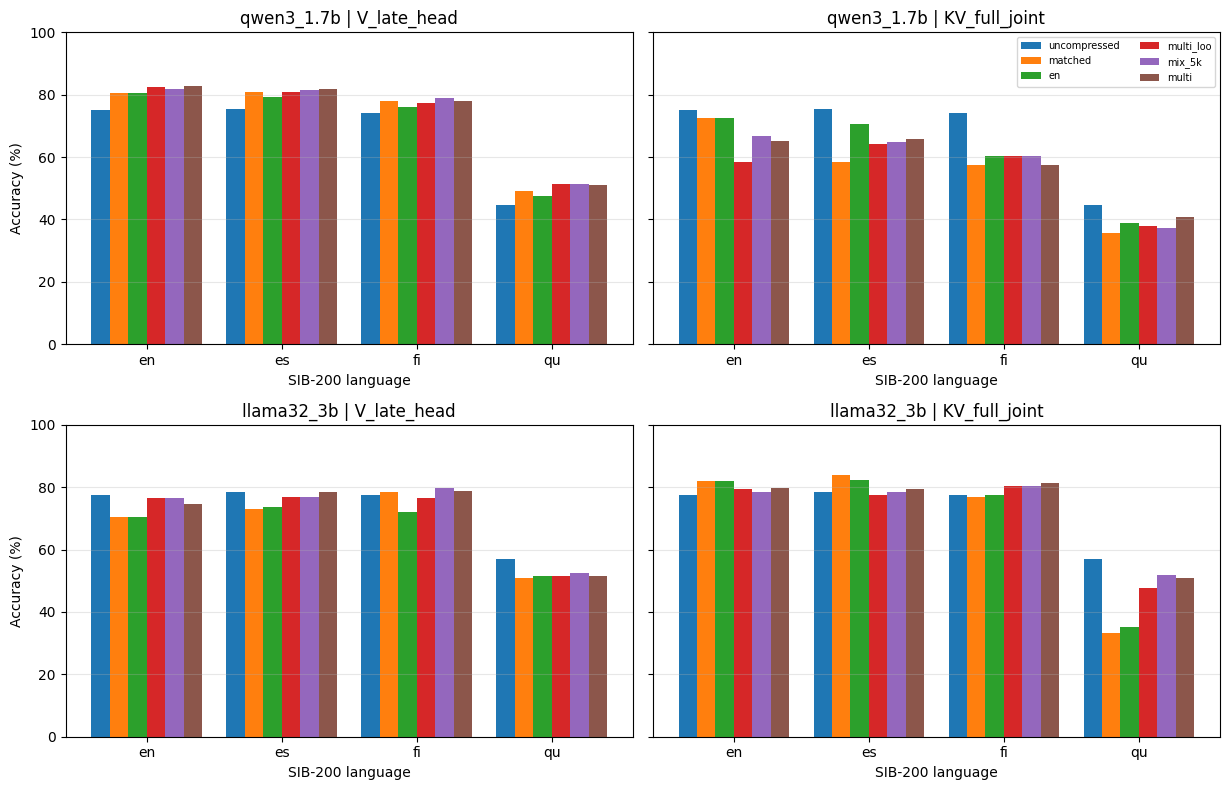

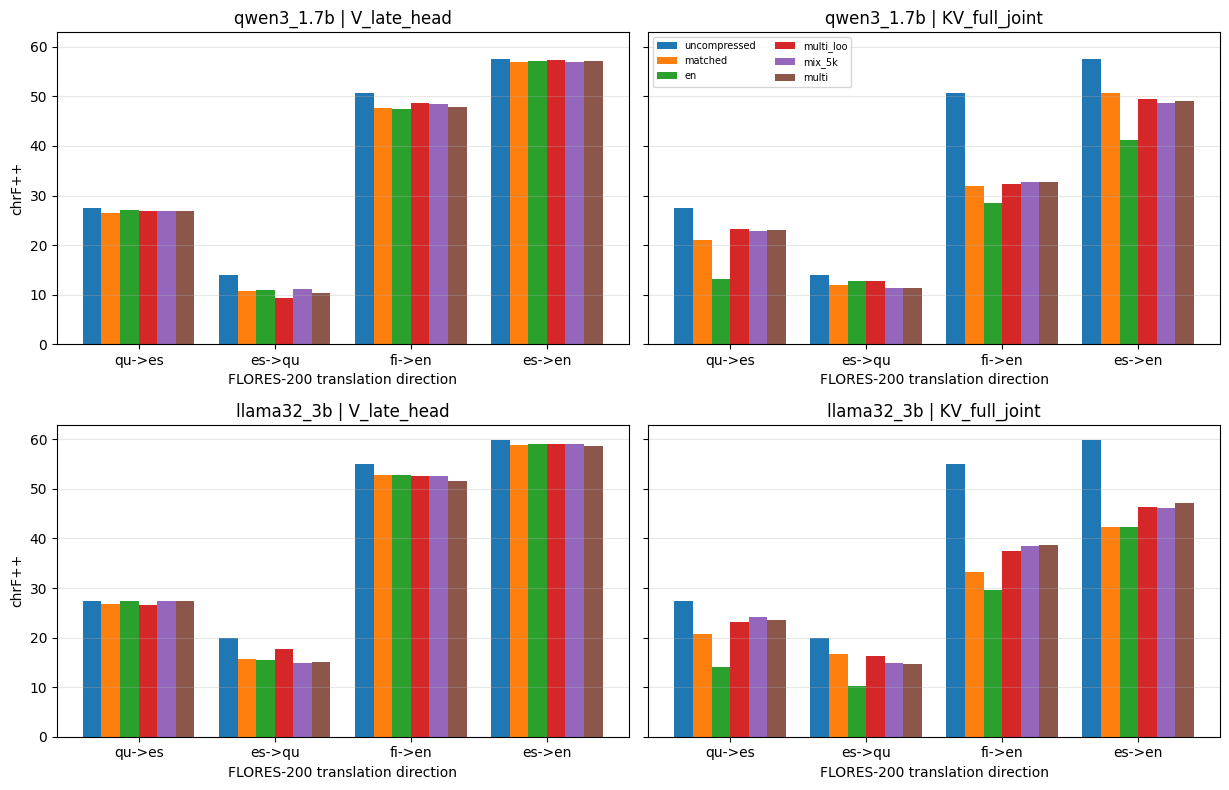

In [7]:
model_tags = [m[0] for m in MODELS]
regimes_plot = ["V_late_head", "KV_full_joint"]
show_srcs = ["uncompressed", "matched", en_code, "multi_loo", "mix_5k", "multi"]

# Fig 1: SIB-200 Topic Classification Accuracy (%)
fig, axes = plt.subplots(len(model_tags), len(regimes_plot), figsize=(6.2 * len(regimes_plot), 4.0 * len(model_tags)),
                         sharey=True, squeeze=False)
w = 0.82 / len(show_srcs)
for i, mtag in enumerate(model_tags):
    for j, rname in enumerate(regimes_plot):
        ax = axes[i][j]
        x = np.arange(len(LANGS))
        for k, s in enumerate(show_srcs):
            vals = []
            for lang in LANGS:
                if s == "uncompressed":
                    q = sib_df[(sib_df.model == mtag) & (sib_df.regime == "uncompressed") & (sib_df.target == lang)]
                else:
                    s_use = "matched" if (s == en_code and lang == en_code) else s
                    q = sib_df[(sib_df.model == mtag) & (sib_df.regime == rname) & (sib_df.target == lang) & (sib_df.source == s_use)]
                vals.append(q.acc.iloc[0] if len(q) else np.nan)
            ax.bar(x + (k - (len(show_srcs) - 1) / 2) * w, vals, w, label=s)
        ax.set_xticks(x, LANGS); ax.set_ylim(0, 100)
        ax.set_xlabel("SIB-200 language"); ax.set_title(f"{mtag} | {rname}")
        ax.grid(axis="y", alpha=0.3)
    axes[i][0].set_ylabel("Accuracy (%)")
axes[0][-1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig1_sib200_downstream.png"), dpi=150)
plt.show()

# Fig 2: FLORES-200 Autoregressive Translation chrF++
dir_names = [f"{a}->{b}" for a, b, _ in MT_DIRS]
fig, axes = plt.subplots(len(model_tags), len(regimes_plot), figsize=(6.2 * len(regimes_plot), 4.0 * len(model_tags)),
                         sharey=True, squeeze=False)
for i, mtag in enumerate(model_tags):
    for j, rname in enumerate(regimes_plot):
        ax = axes[i][j]
        x = np.arange(len(dir_names))
        for k, s in enumerate(show_srcs):
            vals = []
            for dn in dir_names:
                if s == "uncompressed":
                    q = mt_df[(mt_df.model == mtag) & (mt_df.regime == "uncompressed") & (mt_df.direction == dn)]
                else:
                    q = mt_df[(mt_df.model == mtag) & (mt_df.regime == rname) & (mt_df.direction == dn) & (mt_df.source == s)]
                vals.append(q.chrfpp.iloc[0] if len(q) else np.nan)
            ax.bar(x + (k - (len(show_srcs) - 1) / 2) * w, vals, w, label=s)
        ax.set_xticks(x, dir_names)
        ax.set_xlabel("FLORES-200 translation direction"); ax.set_title(f"{mtag} | {rname}")
        ax.grid(axis="y", alpha=0.3)
    axes[i][0].set_ylabel("chrF++")
axes[0][-1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig2_mt_flores_downstream.png"), dpi=150)
plt.show()

## 5. Reading guide

1. **SIB-200 (`fig1_sib200_downstream.png`, `sib200_results.csv`):**
   - Look at `KV_full_joint` (4× full-model compression, `layers 3–27`) and `V_late_head`: does English-only calibration drop accuracy on `qu`, `fi`, and `es`, and does `mix_5k` (`~5k` Wikipedia tokens, strictly cross-domain!) restore accuracy to `matched` / `uncompressed` levels?
2. **FLORES-200 Translation (`fig2_mt_flores_downstream.png`, `mt_flores_results.csv`, `mt_sample_outputs.json`):**
   - Because this runs **true `use_cache=True` autoregressive decoding**, any degradation in `qu → es`, `es → qu`, `fi → en`, or `es → en` directly proves real-world KV-cache deployment impact — and the saved qualitative translations in `mt_sample_outputs.json` make a great table for the paper!